**Q3.** Write a Python program to analyze a directed social network using NetworkX and a Kaggle Facebook/Twitter graph dataset.
(a) Load the directed graph and display its basic properties, including the number of nodes and edges.
(b) Visualize the degree distribution of the network.
(c) Calculate Betweenness Centrality, Eigenvector Centrality, and PageRank to identify influential nodes.
(d) Display the top 5 nodes according to each centrality measure.

In [2]:
import networkx as nx
import matplotlib.pyplot as plt

In [3]:
# (a) Load the directed graph and display basic properties
# A directed growing network with 50 nodes (simulates a follower network)
G = nx.gn_graph(50, seed=42)
G = G.reverse()   # reverse edges to simulate "followers"

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
print("Is directed:", G.is_directed())
print("Density:", round(nx.density(G), 4))

Number of nodes: 50
Number of edges: 49
Is directed: True
Density: 0.02


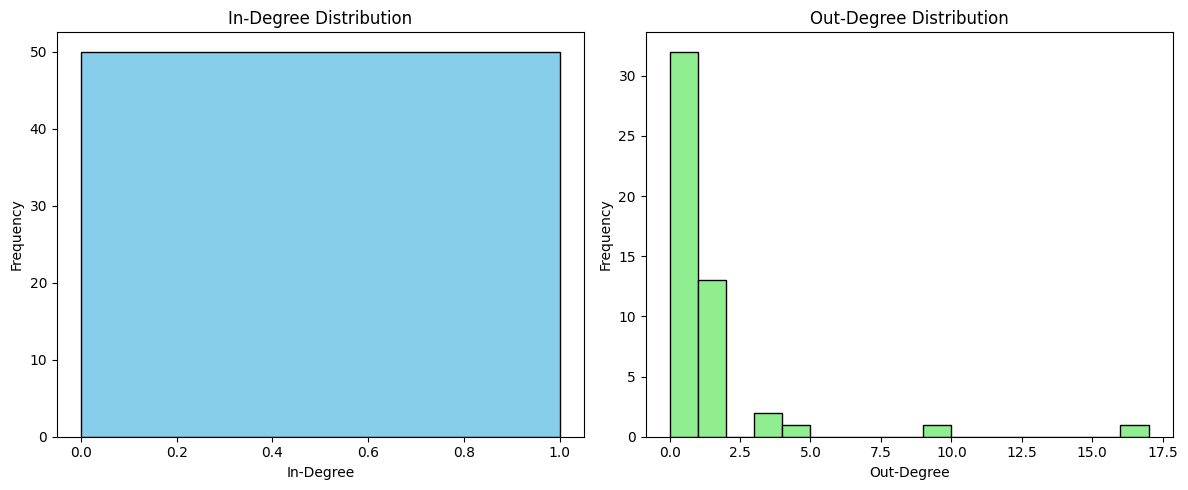

In [8]:
# (b) Degree distribution
in_degrees = [d for n, d in G.in_degree()]
out_degrees = [d for n, d in G.out_degree()]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(in_degrees, bins=range(max(in_degrees) + 1), color='skyblue', edgecolor='black')
plt.title('In-Degree Distribution')
plt.xlabel('In-Degree')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
plt.hist(out_degrees, bins=range(max(out_degrees) + 1), color='lightgreen', edgecolor='black')
plt.title('Out-Degree Distribution')
plt.xlabel('Out-Degree')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

In [9]:
# (c) Centrality measures
betweenness = nx.betweenness_centrality(G)
pagerank = nx.pagerank(G)

# This graph has no cycles, so eigenvector centrality on the directed graph is not meaningful.
# We compute it on the undirected version instead.
eigenvector = nx.eigenvector_centrality(G.to_undirected(), max_iter=1000)

In [10]:
# (d) Top 5 nodes for each centrality measure
def top5(scores, name):
    print(f"\nTop 5 nodes by {name}:")
    for node, score in sorted(scores.items(), key=lambda x: x[1], reverse=True)[:5]:
        print(f"  Node {node}: {score:.4f}")

top5(betweenness, "Betweenness Centrality")
top5(eigenvector, "Eigenvector Centrality")
top5(pagerank, "PageRank")


Top 5 nodes by Betweenness Centrality:
  Node 3: 0.0077
  Node 22: 0.0051
  Node 13: 0.0043
  Node 6: 0.0034
  Node 11: 0.0026

Top 5 nodes by Eigenvector Centrality:
  Node 0: 0.6596
  Node 3: 0.3043
  Node 11: 0.1955
  Node 1: 0.1621
  Node 18: 0.1621

Top 5 nodes by PageRank:
  Node 38: 0.0391
  Node 10: 0.0373
  Node 35: 0.0373
  Node 40: 0.0331
  Node 39: 0.0302


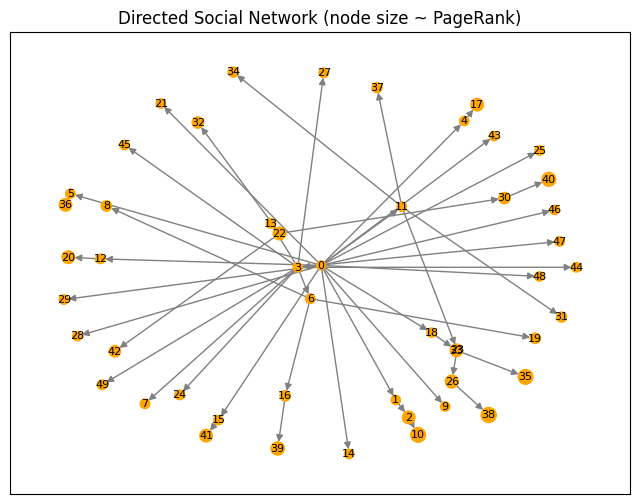

In [11]:
# Visualize the network (node size = PageRank)
plt.figure(figsize=(8, 6))
pos = nx.spring_layout(G, seed=42)
sizes = [3000 * pagerank[n] for n in G]
nx.draw_networkx(G, pos, node_size=sizes, node_color='orange', edge_color='gray', font_size=8)
plt.title('Directed Social Network (node size ~ PageRank)')
plt.show()